In [ ]:
import sys
sys.path.append("../")

import pulse_simulator as ps

import numpy as np
import matplotlib.pyplot as plt
import jax

# qiskit
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.quantum_info import process_fidelity
import qiskit_dynamics

# jax stuff
jax.config.update("jax_enable_x64", True)
qiskit_dynamics.array.Array.set_default_backend("jax")

# Check if GPU is available
print("jax backend: ", jax.default_backend())

/home/andy/Documents/Research/Projects/pulse-simulator/pulse-simulator/.venv/lib/python3.12/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


jax backend:  gpu


In [33]:
num_qubits = 3

# Basis gates
basis_gates = ["id", "rz", "sx", "x", "ecr"]

# Linear connectivity (with 2QB gates in both directions)
coupling_map = (
    [[i, i + 1] for i in range(num_qubits - 1)] 
    + [[i + 1, i] for i in range(num_qubits - 1)]
)

backend = GenericBackendV2(
    num_qubits=num_qubits, 
    basis_gates=basis_gates,
    coupling_map=coupling_map,
)

# Select subset of registers to simulate
registers = [0, 1]

# backend.coupling_map.draw()

In [34]:
# e^x = 1 + x + x^2/2! + x^3/3! + ...
# exp(-iH * Δt) = I - iHΔt - H^2(Δt)^2/2! - H^3(Δt)^3/3! - ...

Notice that the x's keep growing in power. If x was "meters", then e^x would require you to add up x meters with x meters squared with x meters cubed.

In [35]:
# d/dt|ψ⟩ = -i H|ψ⟩
# |ψ(t)⟩ = U(t)|ψ(0)⟩ = exp(-iH * Δt)|ψ(0)⟩
# H * Δt = a(t) * X * Δt
# GHz: 1e9, ns: 1e-9

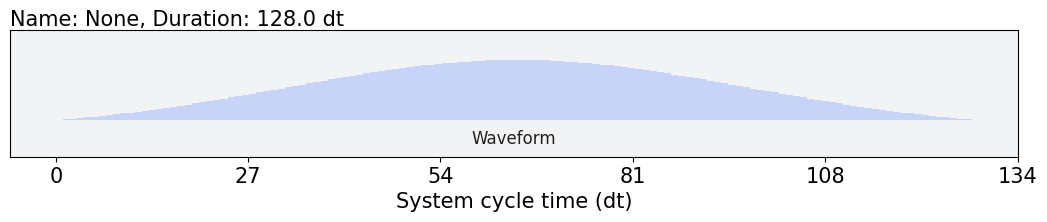

In [36]:
ns = 1e-9
dt_simulation =  backend.dt / ns
desired_1qb_samples = 120
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_samples)

default_1qb_gateset = ps.default_single_qubit_gateset(
    ["X1", "X2", "SX1", "SX2", "ID1", "ID2"], duration_1qb, dt_simulation
)

default_1qb_gateset["X1"].draw()

In [37]:
from qiskit.circuit.random import random_circuit

depth = 4
seed = 17
# This circuit will only use 1QB gates
rand_circ = random_circuit(len(registers), seed, max_operands=1)

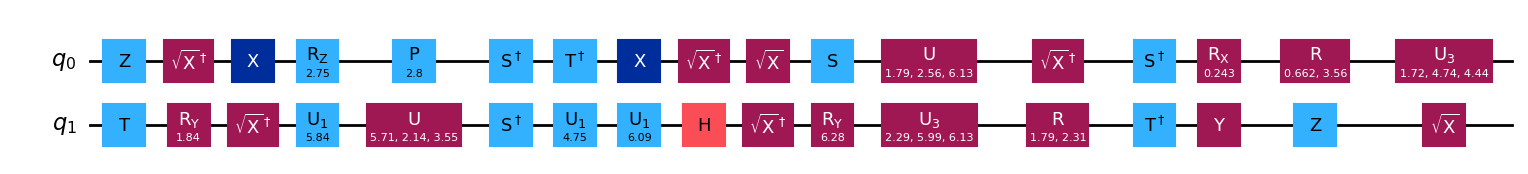

In [38]:
rand_circ.draw('mpl')

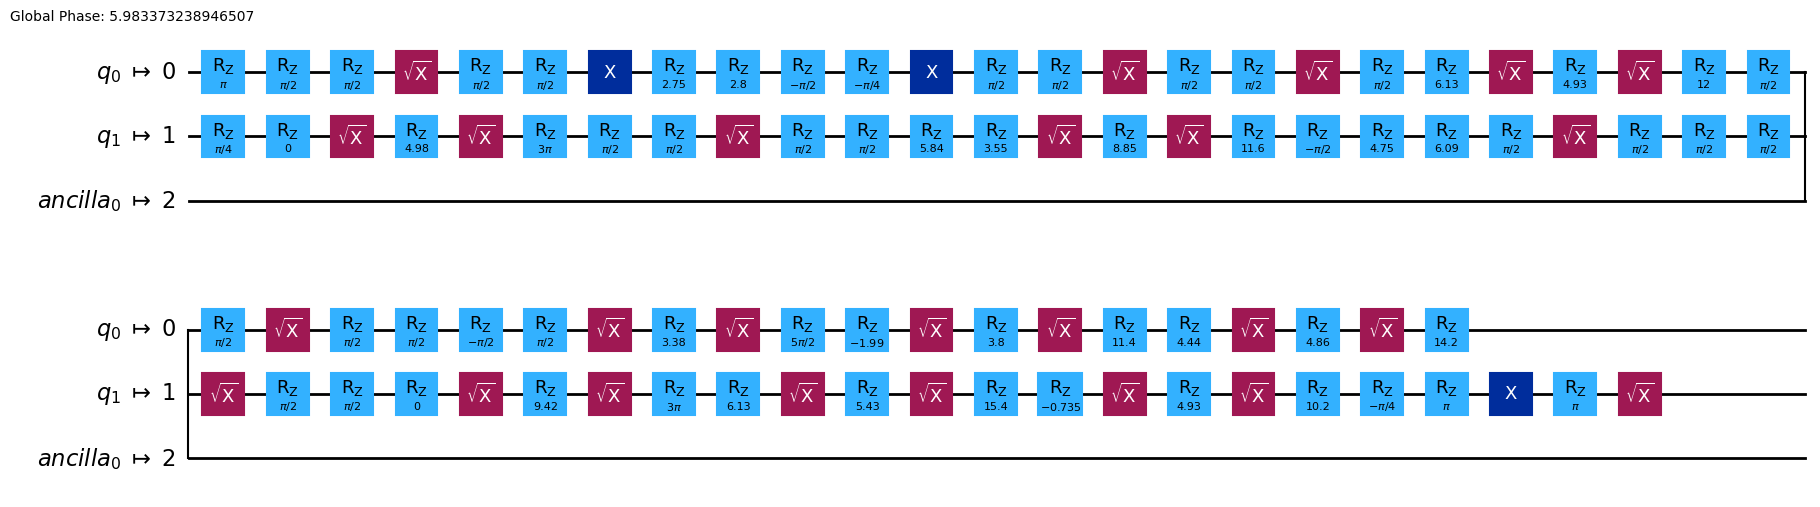

In [54]:
from qiskit import transpile

transpile(rand_circ, backend, optimization_level=0).draw('mpl')
# transpile(rand_circ, backend, optimization_level=1).draw('mpl')

In [39]:
simulator = ps.Simulator(registers, backend)

In [ ]:
# Build the pulse simulator
simulator = ps.Simulator(registers, backend)

# Add some errors to make it interesting!
res = simulator.simulate_circuit(
    rand_circ, 
    default_1qb_gateset, 
    None, # default 2QB gateset
    dt_simulation, 
    include_crosstalk=True, 
    include_dissipation=True,
    gpu=True,
)

In [55]:
moments = simulator.get_moments()
moments

[{0: 6.283185307179586, 1: 0.7853981633974483},
 {0: 'SX', 1: 'SX'},
 {0: 3.141592653589793, 1: 4.981784893888333},
 {0: 'X', 1: 'SX'},
 {0: 3.1965645520697414, 1: 12.566370614359172},
 {0: 'X', 1: 'SX'},
 {0: 3.141592653589793, 1: 12.539981352869354},
 {0: 'SX', 1: 'SX'},
 {0: 3.141592653589793, 1: 8.85054291511997},
 {0: 'SX', 1: 'SX'},
 {0: 7.696582902397343, 1: 22.401849615660687},
 {0: 'SX', 1: 'SX'},
 {0: 4.934495217057673, 1: 4.71238898038469},
 {0: 'SX', 1: 'SX'},
 {0: 15.129498630619551, 1: 3.141592653589793},
 {0: 'SX', 1: 'SX'},
 {0: 3.141592653589793, 1: 9.422829376379347},
 {0: 'SX', 1: 'SX'},
 {0: 3.384396873820686, 1: 15.558846813038974},
 {0: 'SX', 1: 'SX'},
 {0: 5.861893553097026, 1: 5.432825840112063},
 {0: 'SX', 1: 'SX'},
 {0: 3.803606342005807, 1: 14.676929411975284},
 {0: 'SX', 1: 'SX'},
 {0: 15.854044045155206, 1: 4.927548115023065},
 {0: 'SX', 1: 'SX'},
 {0: 4.864967568145401, 1: 12.515642652525042},
 {0: 'SX', 1: 'X'},
 {1: 3.141592653589793},
 {1: 'SX', 0: 'ID'

(1e-06, 1)

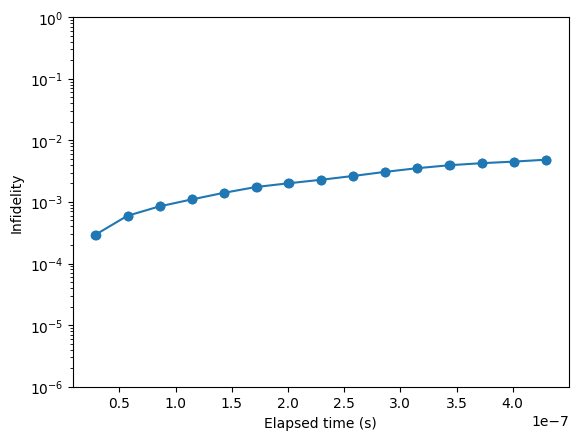

In [61]:
# Let's check in on the simulation after each gate
moments = simulator.get_moments()
measure_times = np.cumsum(
    ps.durations_of_moments(moments, duration_1qb, 0.0)
) * backend.dt

# These were the expected outcomes
U_goals = [] 
for i in range(len(moments)):
    U_goals.append(ps.build_operator(moments[0:i+1], registers))

# How did we do?
fidelities = np.array([process_fidelity(R, U) for R, U in zip(res[1:], U_goals)])

# Plot the result
fig, ax = plt.subplots(1)
ax.plot(measure_times[1:], 1 - fidelities[1:], marker="o")
ax.set_xlabel("Elapsed time (s)")
ax.set_ylabel("Infidelity")
ax.set_yscale("log")
ax.set_ylim(1e-6, 1)

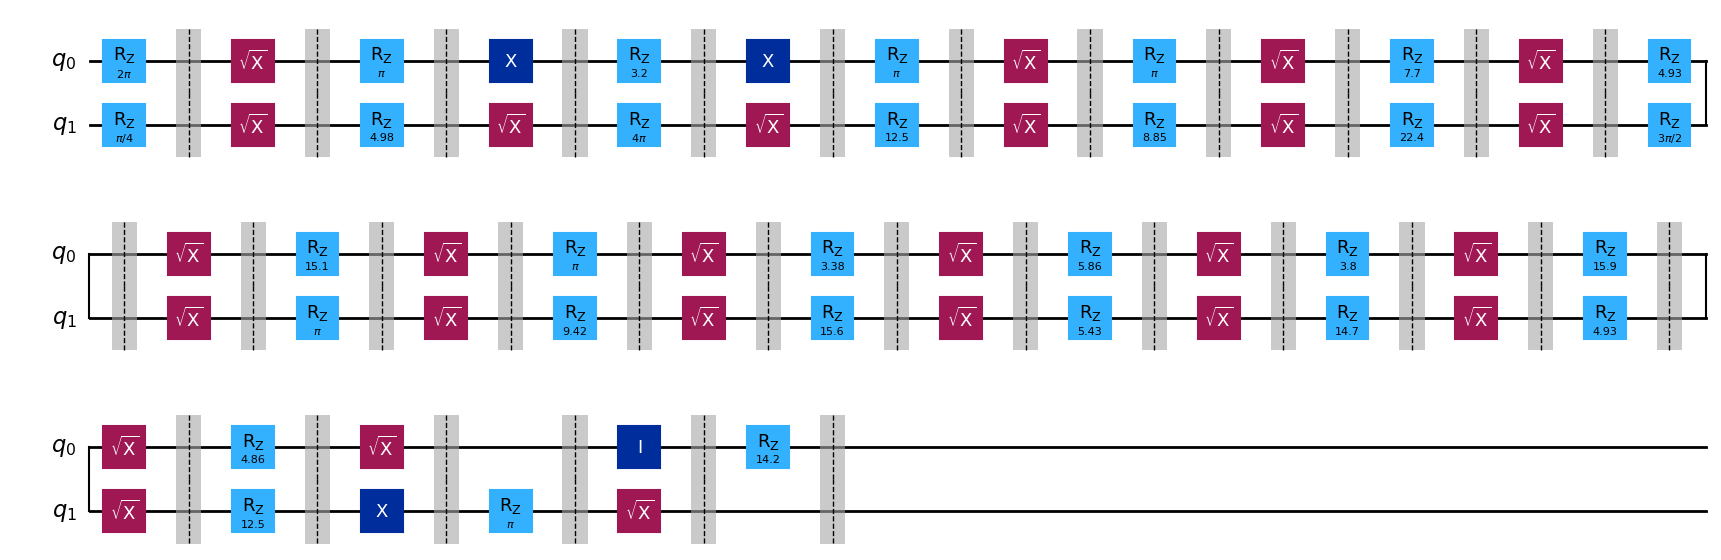

In [62]:
simulator.build_circuit(insert_barriers=True).draw('mpl')